# Entanglement entropy analysis
Tracks the Von Neumann entanglement entropy of `MerlinTunableSimple`'s quantum layer
(default bipartition: encoded modes vs. the extra mode) over training, alongside model
accuracy (relative L2 error), averaged over seeds.

Settings: same baseline PDE/sampler config as `Reproducibility.ipynb` (freq=0.5, default
sampler, 600 epochs), same seeds as `ModelSize_scaling.ipynb`.

## 0 - Setup

In [1]:
%load_ext autoreload
%autoreload 2

import torch
import numpy as np
import matplotlib
matplotlib.rcParams['figure.dpi'] = 120

import sys
import os

# Adds the parent directory (root of your project) to the python path
sys.path.append(os.path.abspath(os.path.join('..')))

from src.models  import MerlinTunableSimple
from src.pde     import HeatEquation
from src.loss    import total_loss
from src.train   import train
from src.eval    import evaluate
from src.plotter import plot_entropy_accuracy_trajectory

# Prefer CUDA, then Apple Silicon GPU (MPS), then fall back to CPU.
if torch.cuda.is_available():
    device = torch.device('cuda')
elif torch.backends.mps.is_available():
    device = torch.device('mps')
else:
    device = torch.device('cpu')
dtype  = torch.float32
print(f'device: {device}  |  dtype: {dtype}')

device: mps  |  dtype: torch.float32


## 1 - Config

In [2]:
SEEDS = [42] #, 666, 69, 67, 13]
EPOCHS = 5

pde = HeatEquation(freq=0.5)

n_encoding_layers = 2

## 2 - Train for each seed, recording entropy + rel L2 every epoch

`eval_callback` runs `evaluate()` on the full (x, t) grid after every epoch, capturing
both the model's Von Neumann entropy (from its default bipartition) and its relative
L2 error against the exact solution.

In [4]:
entropy_trajectories = []
rel_l2_trajectories = []

for seed in SEEDS:
    print(f"\n{'='*60}\nSeed {seed}\n{'='*60}")
    model = MerlinTunableSimple(n_encoding_layers=n_encoding_layers).to(device)

    entropy_traj = []
    rel_l2_traj = []

    def eval_callback(m, epoch):
        metrics, *_ = evaluate(m, pde, device=device, dtype=dtype, verbose=False)
        entropy_traj.append(metrics["entropy"])
        rel_l2_traj.append(metrics["rel_l2"])

    train(
        model=model, pde=pde, loss_fn=total_loss,
        epochs=EPOCHS, log_every=EPOCHS, seed=seed,
        device=device, dtype=dtype,
        eval_every=1, eval_callback=eval_callback,
    )

    entropy_trajectories.append(entropy_traj)
    rel_l2_trajectories.append(rel_l2_traj)

entropy_trajectories = np.array(entropy_trajectories)  # (n_seeds, epochs)
rel_l2_trajectories  = np.array(rel_l2_trajectories)   # (n_seeds, epochs)


Seed 42
Parameters — total: 398  trainable: 398

Training for 5 epochs on mps  (dtype=torch.float32)
Epoch     1/5 | Loss: 1.5641e+00 | PDE: 8.12e-07 | Cons: 3.11e-02 | IC: 1.04e-01 | BC: 5.22e-01 | Time: 4.4s
Epoch     5/5 | Loss: 1.7516e+00 | PDE: 2.67e-05 | Cons: 5.50e-03 | IC: 1.24e-01 | BC: 5.13e-01 | Time: 19.5s

Done — 19.5s total


## 3 - Aggregate across seeds and plot

Saved: figures/entanglement_entropy/entropy_accuracy_trajectory.png


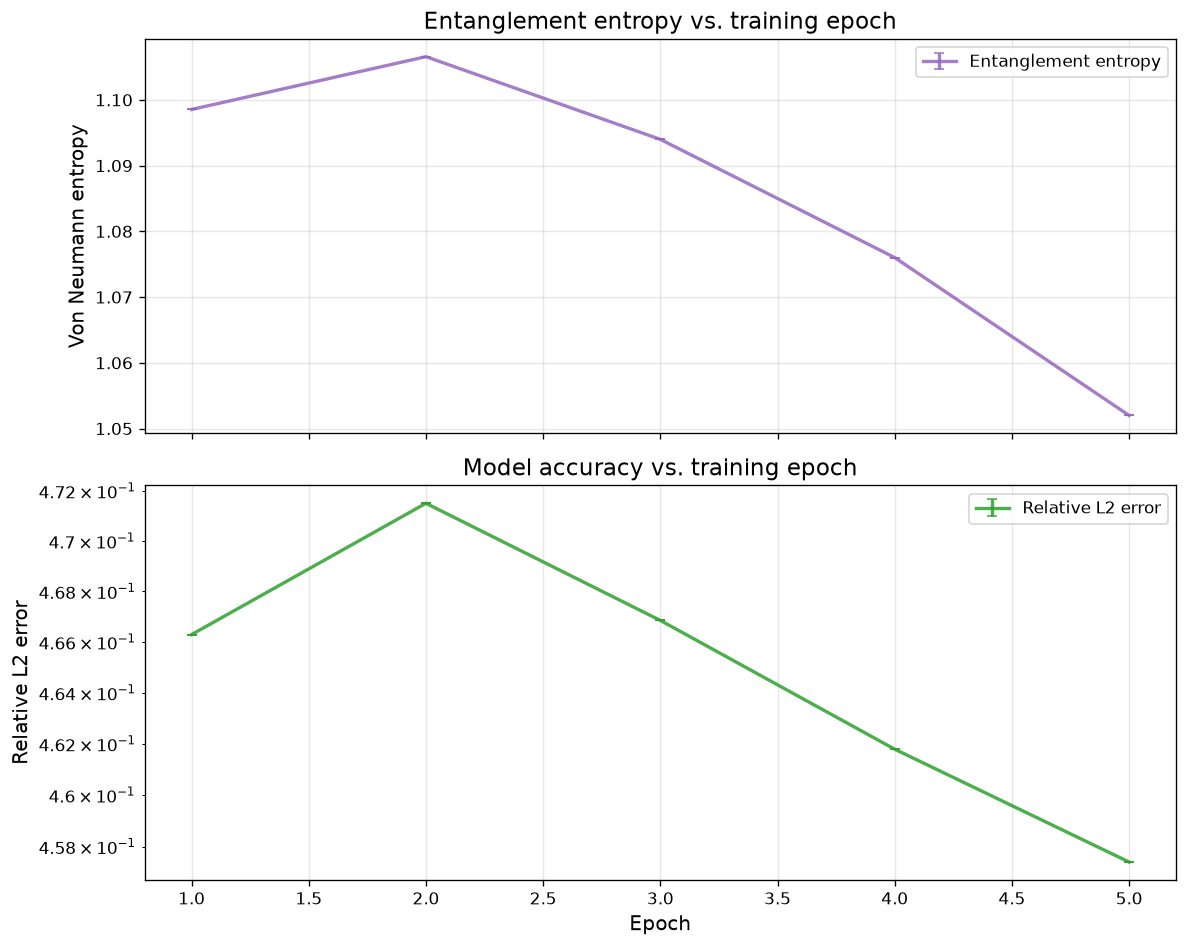

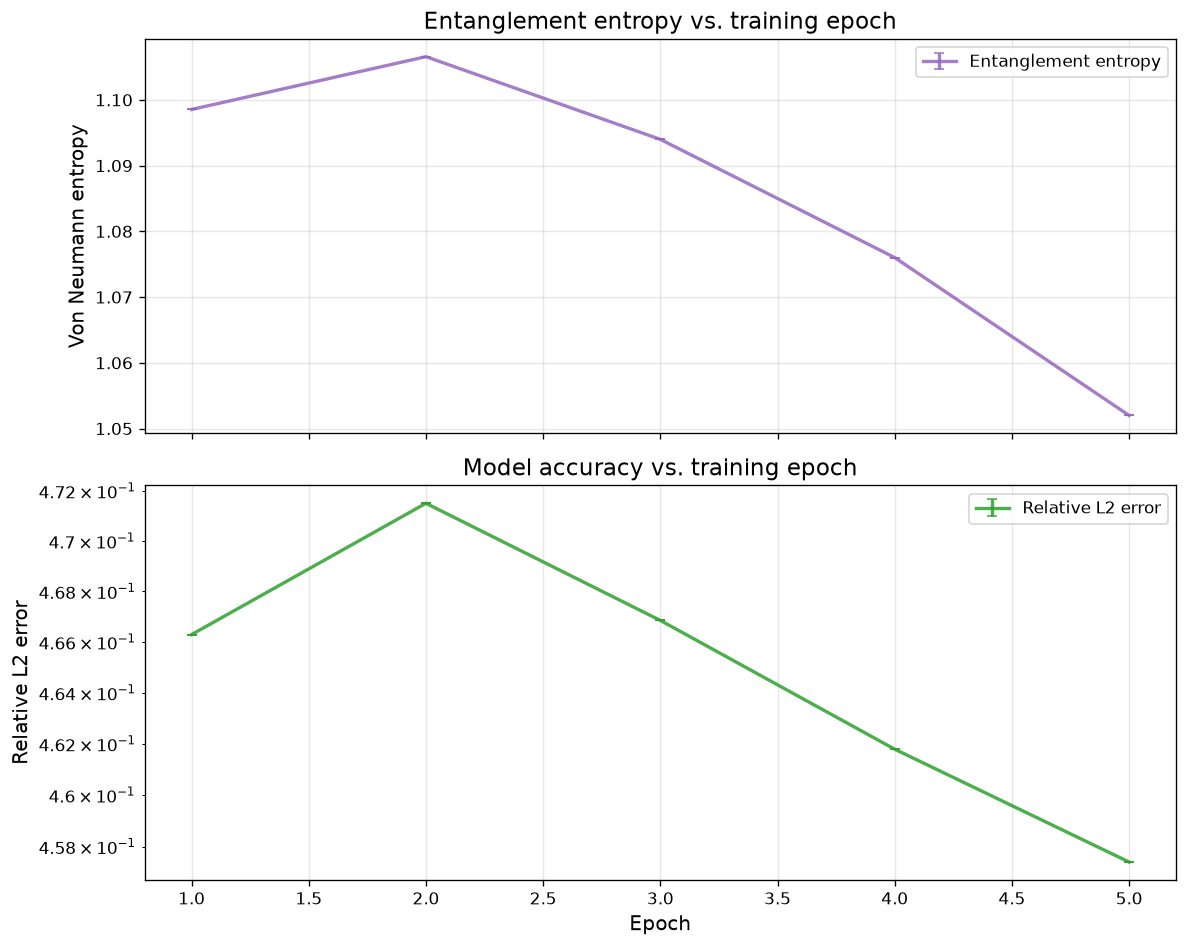

In [5]:
epochs_axis = np.arange(1, EPOCHS + 1)

entropy_mean = entropy_trajectories.mean(axis=0)
entropy_std  = entropy_trajectories.std(axis=0)
rel_l2_mean  = rel_l2_trajectories.mean(axis=0)
rel_l2_std   = rel_l2_trajectories.std(axis=0)

plot_entropy_accuracy_trajectory(
    epochs_axis, entropy_mean, entropy_std, rel_l2_mean, rel_l2_std,
    save_path="figures/entanglement_entropy/entropy_accuracy_trajectory.png",
    show=True,
)

## 4 - Data re-uploading (doubled angle encoding) vs. parameter-matched classical baseline

`MerlinTunableSimple(n_encoding_layers=2)` re-uploads the encoded features through a
second angle-encoding pass over the *same* `feature_size` modes (data re-uploading),
interleaved with an extra trainable entangling layer, instead of growing `feature_size`
itself. This doubles the number of angle-encoding gates while keeping `n_modes` — and
therefore the Fock-basis Hilbert space / simulation cost — identical to the 1-layer
baseline (growing `feature_size` instead would grow the Hilbert space combinatorially:
35 -> 1287 dimensions for feature_size 4 -> 8, a ~37x blowup).

`match_classical_param_count` builds a classical MLP (`ClassicalTunableSimple`) with the
exact same total trainable parameter count as the 2-layer quantum model, so accuracy
differences below reflect architecture, not capacity budget.

**Runtime note:** the section 2 baseline run above (1 seed, 600 epochs) took ~44 minutes
on this M3's MPS backend. This section trains 3 models, so a full run at the same
settings is ~2+ hours. Consider lowering `COMPARISON_EPOCHS` / `COMPARISON_SEEDS` below
for a first pass.

In [ ]:
from src.models import ClassicalTunableSimple, match_classical_param_count

COMPARISON_SEEDS = SEEDS
COMPARISON_EPOCHS = EPOCHS

_reference_quantum = MerlinTunableSimple(feature_size=4, n_encoding_layers=2)

MODEL_BUILDERS = {
    "quantum (1 encoding layer)": lambda: MerlinTunableSimple(feature_size=4, n_encoding_layers=1),
    "quantum (2 encoding layers)": lambda: MerlinTunableSimple(feature_size=4, n_encoding_layers=2),
    "classical (param-matched)": lambda: match_classical_param_count(
        _reference_quantum, feature_size=4, n_encoding_layers=2
    ),
}

for name, build in MODEL_BUILDERS.items():
    n_params = sum(p.numel() for p in build().parameters())
    print(f"{name:28s} total params: {n_params}")

### 4.1 - Train each model across seeds

Same per-epoch entropy + rel L2 tracking as section 2. The classical model's `forward`
returns `(u, ux_hat)` with no entropy term — `evaluate()` already handles that (entropy
is `None` when the model doesn't return one), so `entropy_traj` stays a list of `None`s
for the classical run and is skipped when plotting.

In [ ]:
comparison_rel_l2 = {}   # name -> (n_seeds, epochs)
comparison_entropy = {}  # name -> (n_seeds, epochs), quantum models only

for name, build in MODEL_BUILDERS.items():
    rel_l2_runs = []
    entropy_runs = []

    for seed in COMPARISON_SEEDS:
        print(f"\n{'='*60}\n{name} — seed {seed}\n{'='*60}")
        model = build().to(device)

        rel_l2_traj = []
        entropy_traj = []

        def eval_callback(m, epoch):
            metrics, *_ = evaluate(m, pde, device=device, dtype=dtype, verbose=False)
            rel_l2_traj.append(metrics["rel_l2"])
            entropy_traj.append(metrics["entropy"])

        train(
            model=model, pde=pde, loss_fn=total_loss,
            epochs=COMPARISON_EPOCHS, log_every=COMPARISON_EPOCHS, seed=seed,
            device=device, dtype=dtype,
            eval_every=1, eval_callback=eval_callback,
        )

        rel_l2_runs.append(rel_l2_traj)
        entropy_runs.append(entropy_traj)

    comparison_rel_l2[name] = np.array(rel_l2_runs)
    if entropy_runs[0][0] is not None:
        comparison_entropy[name] = np.array(entropy_runs)

### 4.2 - Aggregate across seeds and plot

In [ ]:
from src.plotter import plot_model_comparison_trajectory

comparison_epochs_axis = np.arange(1, COMPARISON_EPOCHS + 1)

rel_l2_by_model = {
    name: (arr.mean(axis=0), arr.std(axis=0))
    for name, arr in comparison_rel_l2.items()
}
entropy_by_model = {
    name: (arr.mean(axis=0), arr.std(axis=0))
    for name, arr in comparison_entropy.items()
}

plot_model_comparison_trajectory(
    comparison_epochs_axis,
    rel_l2_by_model,
    entropy_by_model=entropy_by_model,
    save_path="figures/entanglement_entropy/encoding_layers_vs_classical.png",
    show=True,
)